In [1]:
%pip install shapely
%pip install numpy matplotlib scipy

Overwriting a_star.py


In [2]:
%load_ext autoreload
%autoreload 2

import numpy as np
import matplotlib.pyplot as plt
import scipy.interpolate
from shapely import box

from utils import Workspace2D
# from a_star import AStar

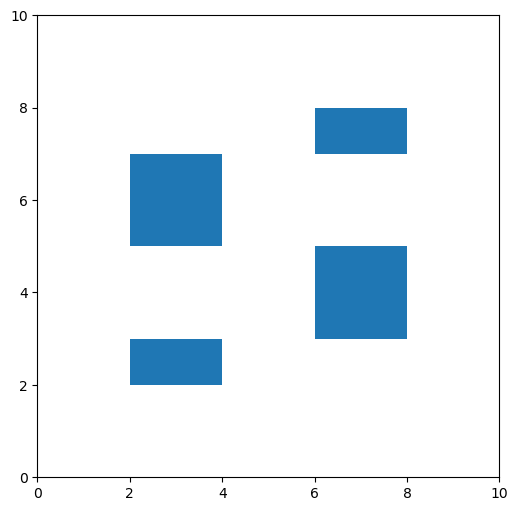

In [4]:
workspace = Workspace2D(10, 10)
obstacles = [box(2, 2, 4, 3), box(6, 7, 8, 8), box(6, 3, 8, 5), box(2, 5, 4, 7)]
workspace.set_obstacles(obstacles)
workspace.plot()

In [5]:
x_init = (1, 9)
x_goal = (9, 1)
astar = AStar(workspace, x_init, x_goal)
if not astar.solve():
    print("No path found")
else:
    astar.plot_path()
    astar.plot_tree()

<class 'NameError'>: name 'AStar' is not defined

In [1]:
def compute_smooth_plan( path: list[tuple[float]], spline_alpha: float=0.05) -> np.ndarray:
    """
    Compute a smoothed path from the given A* path.
    Args:
        path: A* solution path
        spline_alpha: smoothing factor, larger means more smoothing
    Returns:
        Smoothed path array, shape (N, 2) where N is the number of path points.
    """
    # Ensure path is a numpy array
    path = np.asarray(path)

    # Compute and set the following variables:
    #   1. s: 
    #      Compute an array of arclengths, s, for each planned waypoint based on
    #      the Euclidean distance between points.
    #
    #   2. path_x_spline, path_y_spline (scipy.interpolate.BSpline):
    #      Fit cubic splines to the x and y coordinates of the path separately
    #      with respect to the computed time stamp array.
    
    ##### YOUR CODE STARTS HERE #####
    # 1. Tính độ dài cung tích lũy (Cumulative Arc Length) s
    # Tính khoảng cách Euclidean giữa các điểm waypoint liên tiếp
    diffs = np.diff(path, axis=0)  # Shape (N-1, 2)
    segment_lengths = np.linalg.norm(diffs, axis=1)  # Shape (N-1,)
    
    # Chuỗi độ dài cung bắt đầu từ 0 và cộng dồn qua từng điểm
    s = np.zeros(len(path))
    s[1:] = np.cumsum(segment_lengths)

    # 2. Khớp cubic B-spline độc lập cho tọa độ X và Y theo biến số s
    # make_splrep trả về đối tượng scipy.interpolate.BSpline
    path_x_spline = scipy.interpolate.make_splrep(s, path[:, 0], s=spline_alpha)
    path_y_spline = scipy.interpolate.make_splrep(s, path[:, 1], s=spline_alpha)
    ###### YOUR CODE ENDS HERE ######

    # Compute smooth path from the interpolation
    x_smooth = scipy.interpolate.splev(s, path_x_spline, der=0)
    y_smooth = scipy.interpolate.splev(s, path_y_spline, der=0)
    return np.column_stack((x_smooth, y_smooth))


x_init = (1, 9)
x_goal = (9, 1)
astar = AStar(workspace, x_init, x_goal)
if not astar.solve():
    print("No path found")
# Compute smooth plan from A* path
smooth_plan = compute_smooth_plan(astar.path)

# Plot A* path and the smooth path
astar.plot_path(fig_size=10)
plt.plot(smooth_plan[:, 0], smooth_plan[:, 1], 'r-', label='Smoothed Path')
plt.legend()
plt.title('Path Smoothing')

<class 'NameError'>: name 'AStar' is not defined